<a href="https://colab.research.google.com/github/asndjkasdnjkasdjnkasdj/-Lab01_EDA_Azocar_Benjamin/blob/main/Actividad2_6DM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



> ---
## 1. Carga de datos

### 1.1 Descripción del dataset
El dataset corresponde a "The Bread Basket", una panadería de Edinburgh, y contiene los pedidos de sus clientes entre octubre de 2016 y abril de 2017.

- **Transacción:** una compra o boleta de un cliente, identificada por el número de la columna `TransactionNo`. Varias filas con el mismo número pertenecen a la misma compra.
- **Ítem:** cada producto comprado dentro de una transacción, registrado en la columna `Items` (por ejemplo, coffee o bread).
- **Cantidad de transacciones e ítems distintos:** el dataset tiene **[N]** transacciones distintas y **[M]** ítems distintos antes de la limpieza (según la celda 1.4).




In [8]:
import warnings
warnings.filterwarnings("ignore")   # oculta avisos internos de Colab/Jupyter

import os, glob, time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Si mlxtend no está instalada, descomenta la siguiente línea:
# !pip install mlxtend
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")
print("Librerías cargadas correctamente")

Librerías cargadas correctamente


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [9]:
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
print("Credenciales cargadas desde Colab Secrets (no se muestran por seguridad)")

Credenciales cargadas desde Colab Secrets (no se muestran por seguridad)


In [10]:
import kagglehub

# Si esta línea falla, abre el dataset en Kaggle -> Download -> kagglehub y copia el identificador exacto
path = kagglehub.dataset_download("akashdeepkuila/bakery")
print("Archivos descargados en:", path)

Using Colab cache for faster access to the 'bakery' dataset.
Archivos descargados en: /kaggle/input/bakery


### 1.3 Lectura del archivo transaccional

In [11]:
archivos = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
df = None
for a in archivos:
    cols = pd.read_csv(a, nrows=0).columns.tolist()
    print(os.path.basename(a), "->", cols)
    if df is None and {"TransactionNo", "Items"} <= set(cols):
        archivo = a
        df = pd.read_csv(a)

assert df is not None, "No se encontró un CSV con columnas TransactionNo e Items"
print("\nArchivo usado:", os.path.basename(archivo))
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
df.head()

bakery_sales_revised.csv -> ['Transaction', 'Item', 'date_time', 'period_day', 'weekday_weekend']
Bakery.csv -> ['TransactionNo', 'Items', 'DateTime', 'Daypart', 'DayType']

Archivo usado: Bakery.csv
Filas: 20507 | Columnas: 5


,TransactionNo,Items,DateTime,Daypart,DayType
0,1,Bread,2016-10-30 09:58:11,Morning,Weekend
1,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
2,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
3,3,Hot chocolate,2016-10-30 10:07:57,Morning,Weekend
4,3,Jam,2016-10-30 10:07:57,Morning,Weekend


### 1.4 Exploración inicial

In [12]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print()
print("Transacciones distintas:", df["TransactionNo"].nunique())
print("Ítems distintos (antes de limpiar):", df["Items"].nunique())

Valores nulos por columna:
TransactionNo    0
Items            0
DateTime         0
Daypart          0
DayType          0
dtype: int64

Transacciones distintas: 9465
Ítems distintos (antes de limpiar): 94


---
## 2. Preparación de los datos

### 2.1 Revisión de nombres de ítems
Antes de construir las transacciones hay que detectar **nombres inconsistentes** (mayúsculas, espacios) y **filas que no son productos reales**.

In [13]:
frecuencia_items = df["Items"].value_counts(dropna=False)
print("Top 10 ítems más frecuentes:")
print(frecuencia_items.head(10))
print()
print("Lista completa de nombres (revisa si hay ítems raros o que no sean productos):")
print(sorted(df["Items"].dropna().astype(str).unique()))

Top 10 ítems más frecuentes:
Items
Coffee           5471
Bread            3325
Tea              1435
Cake             1025
Pastry            856
Sandwich          771
Medialuna         616
Hot chocolate     590
Cookies           540
Brownie           379
Name: count, dtype: int64

Lista completa de nombres (revisa si hay ítems raros o que no sean productos):
['Adjustment', 'Afternoon with the baker', 'Alfajores', 'Argentina Night', 'Art Tray', 'Bacon', 'Baguette', 'Bakewell', 'Bare Popcorn', 'Basket', 'Bowl Nic Pitt', 'Bread', 'Bread Pudding', 'Brioche and salami', 'Brownie', 'Cake', 'Caramel bites', 'Cherry me Dried fruit', 'Chicken Stew', 'Chicken sand', 'Chimichurri Oil', 'Chocolates', 'Christmas common', 'Coffee', 'Coffee granules ', 'Coke', 'Cookies', 'Crepes', 'Crisps', 'Drinking chocolate spoons ', 'Duck egg', 'Dulce de Leche', 'Eggs', "Ella's Kitchen Pouches", 'Empanadas', 'Extra Salami or Feta', 'Fairy Doors', 'Farm House', 'Focaccia', 'Frittata', 'Fudge', 'Gift voucher', 'Gin

**Justificación de la limpieza:** eliminé las filas sin ítem y las que no representan productos reales (`none` y `adjustment`), porque no son compras y distorsionarían los conteos: un "ítem" `none` aparecería como si fuera un producto frecuente. Además normalicé los nombres (sin espacios sobrantes y en minúscula) para que el mismo producto no se cuente como dos ítems distintos. Con esto se eliminaron **[X]** filas y quedaron **[N]** transacciones y **[M]** ítems distintos. Las transacciones que solo tenían filas `none` desaparecen, porque ya no tienen ningún producto y no aportan información para las reglas.

### 2.3 Transacciones y codificación one-hot
Apriori trabaja con una tabla de **una fila por transacción y una columna por ítem con valores verdadero/falso**. Primero agrupamos los ítems de cada transacción en una lista (sin repetir ítems dentro de la misma boleta) y luego los codificamos.

In [15]:
n_filas_inicial = len(df)

df_limpio = df.dropna(subset=["Items"]).copy()
# Normalización: quitar espacios y pasar a minúsculas para unificar nombres
df_limpio["Items"] = df_limpio["Items"].astype(str).str.strip().str.lower()

# ✍️ AJUSTA esta lista según lo que viste en 2.1 (nombres ya en minúscula)
no_productos = ["none", "adjustment"]
df_limpio = df_limpio[~df_limpio["Items"].isin(no_productos)]

print("Filas iniciales:", n_filas_inicial)
print("Filas después de limpiar:", len(df_limpio), f"(se eliminaron {n_filas_inicial - len(df_limpio)})")
print("Transacciones que quedan:", df_limpio["TransactionNo"].nunique())
print("Ítems distintos tras la limpieza:", df_limpio["Items"].nunique())

Filas iniciales: 20507
Filas después de limpiar: 20506 (se eliminaron 1)
Transacciones que quedan: 9464
Ítems distintos tras la limpieza: 93


In [16]:
transacciones = (
    df_limpio.groupby("TransactionNo")["Items"]
    .apply(lambda s: sorted(set(s)))
    .tolist()
)
print("Número de transacciones:", len(transacciones))
print("Ejemplos:", transacciones[:5])

largos = pd.Series([len(t) for t in transacciones])
print(f"\nTransacciones con un solo ítem: {(largos == 1).mean():.1%}")
print(f"Promedio de ítems por transacción: {largos.mean():.2f}")

Número de transacciones: 9464
Ejemplos: [['bread'], ['scandinavian'], ['cookies', 'hot chocolate', 'jam'], ['muffin'], ['bread', 'coffee', 'pastry']]

Transacciones con un solo ítem: 41.7%
Promedio de ítems por transacción: 2.00


> Un soporte muy bajo puede generar millones de itemsets y agotar la memoria de Colab. **Empieza alto y baja de forma gradual.**

**Justificación del soporte mínimo:** el gráfico muestra que pocos ítems concentran la mayoría de las compras y que hay una cola larga de productos poco frecuentes. Solo **[X]** ítems tienen soporte ≥ 5 %, **[Y]** tienen ≥ 2 % y **[Z]** tienen ≥ 1 %. Elegí un soporte mínimo inicial de **[0,03]** porque deja fuera los productos muy raros, cuyas reglas se apoyarían en pocas boletas y podrían ser casualidad, pero conserva un número manejable de ítems y combinaciones. Después lo bajo de forma gradual en el experimento.

In [17]:
te = TransactionEncoder()
df_onehot = pd.DataFrame(te.fit(transacciones).transform(transacciones), columns=te.columns_)
print("Tabla codificada:", df_onehot.shape, "(transacciones x ítems)")
df_onehot.head()

Tabla codificada: (9464, 93) (transacciones x ítems)


,afternoon with the baker,alfajores,argentina night,art tray,bacon,baguette,bakewell,bare popcorn,basket,bowl nic pitt,bread,bread pudding,brioche and salami,brownie,cake,caramel bites,cherry me dried fruit,chicken sand,chicken stew,chimichurri oil,chocolates,christmas common,coffee,coffee granules,coke,...,postcard,raspberry shortbread sandwich,raw bars,salad,sandwich,scandinavian,scone,siblings,smoothies,soup,spanish brunch,spread,tacos/fajita,tartine,tea,the bart,the nomad,tiffin,toast,truffles,tshirt,valentine's card,vegan feast,vegan mincepie,victorian sponge
0,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


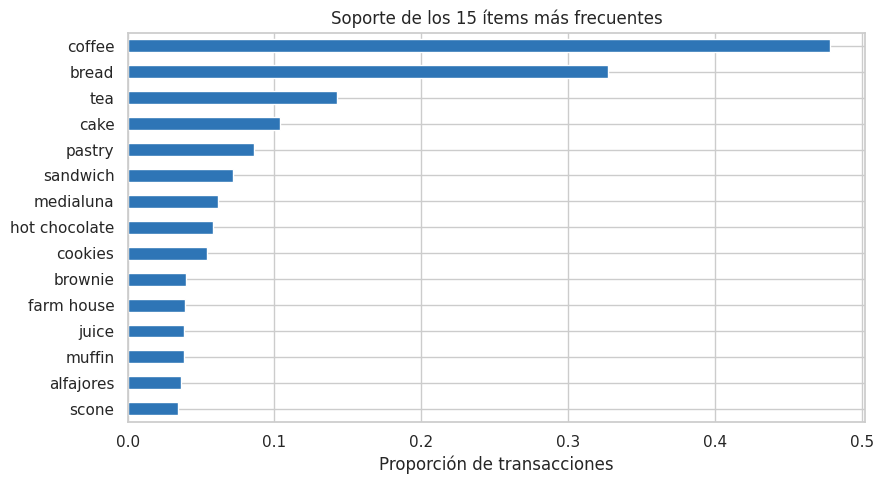

count    93.000000
mean      0.021458
std       0.062739
min       0.000106
25%       0.000634
50%       0.001691
75%       0.015004
max       0.478445
dtype: float64

Ítems con soporte >= 5%: 9
Ítems con soporte >= 2%: 19
Ítems con soporte >= 1%: 30


In [18]:
soporte_items = df_onehot.mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
soporte_items.head(15).sort_values().plot(kind="barh", color="#2E75B6")
plt.title("Soporte de los 15 ítems más frecuentes")
plt.xlabel("Proporción de transacciones")
plt.tight_layout()
plt.show()

print(soporte_items.describe())
print("\nÍtems con soporte >= 5%:", (soporte_items >= 0.05).sum())
print("Ítems con soporte >= 2%:", (soporte_items >= 0.02).sum())
print("Ítems con soporte >= 1%:", (soporte_items >= 0.01).sum())

In [19]:
MIN_SUPPORT = 0.03

itemsets = apriori(df_onehot, min_support=MIN_SUPPORT, use_colnames=True)
itemsets["tamaño"] = itemsets["itemsets"].apply(len)

print(f"Itemsets frecuentes con soporte >= {MIN_SUPPORT:.0%}: {len(itemsets)}")
print(itemsets["tamaño"].value_counts().sort_index().to_string())
itemsets.sort_values("support", ascending=False).head(15)

Itemsets frecuentes con soporte >= 3%: 23
tamaño
1    17
2     6


,support,itemsets,tamaño
4,0.478445,(coffee),1
1,0.327240,(bread),1
15,0.142646,(tea),1
3,0.103867,(cake),1
17,0.090025,"(bread, coffee)",2
11,0.086116,(pastry),1
12,0.071851,(sandwich),1
9,0.061813,(medialuna),1
7,0.058326,(hot chocolate),1
18,0.054734,"(cake, coffee)",2


In [20]:
def generar_reglas(its, confianza_min):
    """Genera reglas por confianza mínima; compatible con distintas versiones de mlxtend."""
    if len(its) == 0 or (its["itemsets"].apply(len) > 1).sum() == 0:
        return pd.DataFrame()
    try:
        return association_rules(its, metric="confidence", min_threshold=confianza_min)
    except TypeError:
        return association_rules(its, num_itemsets=len(df_onehot),
                                 metric="confidence", min_threshold=confianza_min)

def txt(fs):
    return ", ".join(sorted(fs))

In [22]:
MIN_CONF = 0.30

reglas = generar_reglas(itemsets, MIN_CONF)
reglas["antecedente"] = reglas["antecedents"].apply(txt)
reglas["consecuente"] = reglas["consequents"].apply(txt)

reglas = reglas.sort_values("lift", ascending=False)

print(f"Reglas con soporte >= {MIN_SUPPORT:.0%} y confianza >= {MIN_CONF:.0%}: {len(reglas)}")
reglas[["antecedente", "consecuente", "support", "confidence", "lift"]].head(15)

Reglas con soporte >= 3% y confianza >= 30%: 5


,antecedente,consecuente,support,confidence,lift
1,medialuna,coffee,0.035186,0.569231,1.189753
2,pastry,coffee,0.047549,0.552147,1.154046
3,sandwich,coffee,0.038250,0.532353,1.112674
0,cake,coffee,0.054734,0.526958,1.101399
4,tea,coffee,0.049873,0.349630,0.730763


In [23]:
configuraciones = [      #(soporte mínimo, confianza mínima)
    (0.05, 0.50),
    (0.03, 0.40),
    (0.02, 0.30),
    (0.01, 0.30),
]

filas = []
for s, c in configuraciones:
    t0 = time.time()
    its = apriori(df_onehot, min_support=s, use_colnames=True)
    rg = generar_reglas(its, c)
    filas.append({
        "soporte_min": s,
        "confianza_min": c,
        "n_itemsets": len(its),
        "n_reglas": len(rg),
        "lift_max": round(rg["lift"].max(), 2) if len(rg) else None,
        "tiempo_seg": round(time.time() - t0, 2),
    })

tabla_comparativa = pd.DataFrame(filas)
tabla_comparativa

,soporte_min,confianza_min,n_itemsets,n_reglas,lift_max,tiempo_seg
0,0.05,0.5,11,1,1.10,0.07
1,0.03,0.4,23,4,1.19,0.03
2,0.02,0.3,33,10,1.47,0.04
3,0.01,0.3,61,19,1.47,0.06


**Conclusión del experimento**

Al bajar el soporte mínimo de **[0,05]** a **[0,01]**, el número de itemsets pasó de **[A]** a **[B]** y el de reglas de **[C]** a **[D]**, además de aumentar el tiempo de cálculo. Al bajar la confianza mínima también aparecen más reglas, pero más débiles. Con umbrales muy bajos salen muchas reglas de poco respaldo, difíciles de revisar y propensas a ser casualidad; con umbrales muy altos quedan pocas y solo las más obvias. La configuración más razonable para interpretar me pareció **[soporte X y confianza Y]**, porque entrega **[N]** reglas, una cantidad manejable, con respaldo suficiente en las compras.

In [24]:
SOPORTE_FINAL, CONFIANZA_FINAL = 0.02, 0.30

its_final = apriori(df_onehot, min_support=SOPORTE_FINAL, use_colnames=True)
reglas_final = generar_reglas(its_final, CONFIANZA_FINAL)
reglas_final["antecedente"] = reglas_final["antecedents"].apply(txt)
reglas_final["consecuente"] = reglas_final["consequents"].apply(txt)
reglas_final = reglas_final.sort_values("lift", ascending=False)

print("Reglas finales:", len(reglas_final))
reglas_final[["antecedente", "consecuente", "support", "confidence", "lift"]].head(15)

Reglas finales: 10


,antecedente,consecuente,support,confidence,lift
9,toast,coffee,0.023669,0.704403,1.472276
5,medialuna,coffee,0.035186,0.569231,1.189753
6,pastry,coffee,0.047549,0.552147,1.154046
4,juice,coffee,0.020604,0.534247,1.116632
7,sandwich,coffee,0.038250,0.532353,1.112674
1,cake,coffee,0.054734,0.526958,1.101399
2,cookies,coffee,0.028212,0.518447,1.083608
3,hot chocolate,coffee,0.029586,0.507246,1.060199
0,pastry,bread,0.029163,0.338650,1.034868
8,tea,coffee,0.049873,0.349630,0.730763


**Mis 5 reglas más valiosas (una oración de negocio cada una):**

1. Cuando un cliente lleva **[antecedente 1]**, en el **[confianza]%** de los casos también lleva **[consecuente 1]**; esto ocurre en el **[soporte]%** de todas las compras (lift **[valor]**).
2. Cuando un cliente lleva **[antecedente 2]**, en el **[confianza]%** de los casos también lleva **[consecuente 2]**; esto ocurre en el **[soporte]%** de todas las compras (lift **[valor]**).
3. Cuando un cliente lleva **[antecedente 3]**, en el **[confianza]%** de los casos también lleva **[consecuente 3]**; esto ocurre en el **[soporte]%** de todas las compras (lift **[valor]**).
4. Cuando un cliente lleva **[antecedente 4]**, en el **[confianza]%** de los casos también lleva **[consecuente 4]**; esto ocurre en el **[soporte]%** de todas las compras (lift **[valor]**).
5. Cuando un cliente lleva **[antecedente 5]**, en el **[confianza]%** de los casos también lleva **[consecuente 5]**; esto ocurre en el **[soporte]%** de todas las compras (lift **[valor]**).

_Criterio de selección: elegí reglas con lift claramente sobre 1 y soporte suficiente para no depender de unas pocas boletas._

### 5.2 Una regla que descartaría
Una regla puede superar tus umbrales y aun así ser poco útil. Estas son candidatas: **confianza alta pero lift cercano a 1** (el consecuente es tan frecuente que casi cualquier cosa lo "predice").

In [25]:
candidatas = reglas_final[(reglas_final["confidence"] >= 0.5) & (reglas_final["lift"] < 1.2)]
print("Reglas con confianza alta pero lift bajo (candidatas a descartar):", len(candidatas))
candidatas[["antecedente", "consecuente", "support", "confidence", "lift"]].head(10)

Reglas con confianza alta pero lift bajo (candidatas a descartar): 7


,antecedente,consecuente,support,confidence,lift
5,medialuna,coffee,0.035186,0.569231,1.189753
6,pastry,coffee,0.047549,0.552147,1.154046
4,juice,coffee,0.020604,0.534247,1.116632
7,sandwich,coffee,0.038250,0.532353,1.112674
1,cake,coffee,0.054734,0.526958,1.101399
2,cookies,coffee,0.028212,0.518447,1.083608
3,hot chocolate,coffee,0.029586,0.507246,1.060199


**Regla que descarto:** **[antecedente]** ⇒ **[consecuente]**. Supera mis umbrales con una confianza de **[X]%**, pero su lift es de solo **[Y]**, cercano a 1. Esto significa que **[consecuente]** ya aparece en una proporción muy alta de las compras por sí solo (soporte **[Z]%**), así que saber que el cliente llevó **[antecedente]** casi no cambia la probabilidad de que lo lleve. La confianza parece alta solo porque el consecuente es muy popular, no porque exista una asociación real, y por eso no sirve para tomar decisiones como armar un combo.

### 5.3 Verificación a mano de una regla
Como en la Actividad 2.5, contamos directamente sobre las transacciones para comprobar que el cálculo de la librería coincide. Si coincide, la preparación de datos está bien hecha.

In [26]:
def verificar_regla(antecedente, consecuente):
    A, B = set(antecedente), set(consecuente)
    N = len(transacciones)
    nA  = sum(1 for t in transacciones if A <= set(t))
    nB  = sum(1 for t in transacciones if B <= set(t))
    nAB = sum(1 for t in transacciones if (A | B) <= set(t))
    print(f"Regla: {sorted(A)} => {sorted(B)}")
    print(f"N = {N} | boletas con antecedente = {nA} | con consecuente = {nB} | con ambos = {nAB}")
    print(f"Soporte   = {nAB}/{N} = {nAB/N:.4f}")
    print(f"Confianza = {nAB}/{nA} = {nAB/nA:.4f}")
    print(f"Lift      = confianza / soporte(consecuente) = {(nAB/nA)/(nB/N):.4f}")

fila = reglas_final.iloc[0]
verificar_regla(fila["antecedents"], fila["consequents"])
print("\nValores que entregó la librería:")
print(f"Soporte = {fila['support']:.4f} | Confianza = {fila['confidence']:.4f} | Lift = {fila['lift']:.4f}")

Regla: ['toast'] => ['coffee']
N = 9464 | boletas con antecedente = 318 | con consecuente = 4528 | con ambos = 224
Soporte   = 224/9464 = 0.0237
Confianza = 224/318 = 0.7044
Lift      = confianza / soporte(consecuente) = 1.4723

Valores que entregó la librería:
Soporte = 0.0237 | Confianza = 0.7044 | Lift = 1.4723


**Resultado de la verificación:** el conteo directo sobre las transacciones dio soporte **[valor]**, confianza **[valor]** y lift **[valor]**, y estos valores **[coinciden / difieren en el decimal X]** con los que entregó la librería. Esto confirma que la tabla codificada y las transacciones están bien construidas.

### 5.4 Decisión concreta para un administrador
Si las reglas con mayor lift muestran que **[producto A]** y **[producto B]** se compran juntos, el administrador podría armar un combo promocional de ambos y ubicarlos cerca en la vitrina o en la caja. Como el café aparece en una proporción muy alta de las compras, también podría ofrecer un descuento por llevar café junto con los productos que más lo acompañan según las reglas, y reforzar esa oferta en los horarios donde esos productos se venden más. Esta decisión se respalda en la regla **[antecedente] ⇒ [consecuente]** (lift **[valor]**).

---
## 6. Reflexión final
Aprendí que el soporte y la confianza por sí solos no bastan para juzgar una regla: el lift permite ver si la asociación es real o si el consecuente es simplemente muy popular. También vi que los umbrales cambian mucho el resultado: soportes muy bajos generan demasiadas reglas, muchas casuales, y soportes muy altos dejan solo lo obvio. Calcular a mano en la Actividad 2.5 me sirvió para entender qué mide cada métrica, y la librería permite aplicar lo mismo a miles de boletas en segundos. Además comprobé que la limpieza (como quitar `none`) influye directamente en los resultados.

---
## 7. Declaración de uso de herramientas
Utilicé Claude de Anthropic como apoyo para estructurar el notebook, escribir el código base y redactar un borrador de las explicaciones, y también para resolver dudas sobre Kaggle y Colab Secrets. Ejecuté el notebook yo mismo, elegí y ajusté los umbrales, y revisé y completé las interpretaciones con los resultados que obtuve en mi propia ejecución.